In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from IPython.display import clear_output

<Figure size 100x100 with 0 Axes>

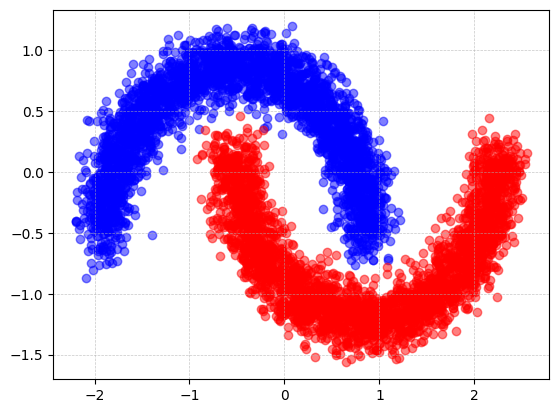

<Figure size 100x100 with 0 Axes>

In [2]:
x, y = make_moons(n_samples=100000, noise=0.1)
x = (x - x.mean()) / x.std()

plt.scatter(x[:,0][y == 0][:3000], x[:,1][y == 0][:3000], alpha=0.5, color="blue")
plt.scatter(x[:,0][y == 1][:3000], x[:,1][y == 1][:3000], alpha=0.5, color="red")
plt.grid(
    True,
    linestyle='--',
    linewidth=0.5,
    alpha=0.7
)
plt.figure(figsize=(1,1))

In [3]:
X = torch.tensor(x, dtype=torch.float32)
diffusion_steps = 40
s = 0.008
timesteps = torch.tensor(range(0, diffusion_steps), dtype=torch.float32)
schedule = torch.cos((timesteps / diffusion_steps + s) / (1 + s) * torch.pi / 2)**2

baralphas = schedule / schedule[0]
betas = 1 - baralphas / torch.concatenate([baralphas[0:1], baralphas[0:-1]])
alphas = 1 - betas


In [4]:
class DiffusionBlock(nn.Module):
    def __init__(self, nunits):
        super(DiffusionBlock, self).__init__()
        self.linear = nn.Linear(nunits, nunits)
        
    def forward(self, x: torch.Tensor):
        x = self.linear(x)
        x = nn.functional.relu(x)
        return x
        
class DiffusionModel(nn.Module):
    def __init__(self, nfeatures: int, nblocks: int = 2, nunits: int = 64):
        super(DiffusionModel, self).__init__()
        
        self.inblock = nn.Linear(nfeatures+1, nunits)
        self.midblocks = nn.ModuleList([DiffusionBlock(nunits) for _ in range(nblocks)])
        self.outblock = nn.Linear(nunits, nfeatures)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        val = torch.hstack([x, t])  # Add t to inputs
        val = self.inblock(val)
        for midblock in self.midblocks:
            val = midblock(val)
        val = self.outblock(val)
        return val

def rbf_kernel(X, Y, sigma=1.0):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    dist = XX - 2 * X @ Y.T + YY.T
    return torch.exp(-dist / (2 * sigma**2))

def mmd(X, Y, sigma=1.0):
    Kxx = rbf_kernel(X, X, sigma)
    Kyy = rbf_kernel(Y, Y, sigma)
    Kxy = rbf_kernel(X, Y, sigma)
    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()

def pairwise_distances(X, Y):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    return XX - 2 * X @ Y.T + YY.T

def knn_fraction_coverage(X, Y, k=1, threshold=0.1):
    dist2 = pairwise_distances(X, Y)
    knn_dist = dist2.topk(k, largest=False, dim=1).values.sqrt()
    covered = (knn_dist.mean(dim=1) <= threshold).float()
    return covered.mean()

def knn_fraction_coverage_both(X, Y, k=1, threshold=0.1):
    cov_xy = knn_fraction_coverage(X, Y, k, threshold)
    cov_yx = knn_fraction_coverage(Y, X, k, threshold)
    return cov_xy, cov_yx

In [7]:
def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

noiselevel = 20
noised, eps = noise(X, torch.full([len(X), 1], fill_value=noiselevel))
denoised = 1 / torch.sqrt(baralphas[noiselevel]) * (noised - torch.sqrt(1 - baralphas[noiselevel]) * eps)

model = DiffusionModel(nfeatures=2, nblocks=4)
device = "cuda"
model = model.to(device)

nepochs = 100
batch_size = 2048


loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.01, total_iters=nepochs)

print(sum(p.numel() for p in model.parameters()))
model

17026


DiffusionModel(
  (inblock): Linear(in_features=3, out_features=64, bias=True)
  (midblocks): ModuleList(
    (0-3): 4 x DiffusionBlock(
      (linear): Linear(in_features=64, out_features=64, bias=True)
    )
  )
  (outblock): Linear(in_features=64, out_features=2, bias=True)
)

In [6]:
class DiffusionBlock(nn.Module):
    def __init__(self, nunits):
        super(DiffusionBlock, self).__init__()
        self.linear = nn.Linear(nunits, nunits)
        
    def forward(self, x: torch.Tensor):
        x = self.linear(x)
        x = nn.functional.relu(x)
        return x
        
class DiffusionModel(nn.Module):
    def __init__(self, nfeatures: int, nblocks: int = 2, nunits: int = 64):
        super(DiffusionModel, self).__init__()
        
        self.inblock = nn.Linear(nfeatures+1, nunits)
        self.midblocks = nn.ModuleList([DiffusionBlock(nunits) for _ in range(nblocks)])
        self.outblock = nn.Linear(nunits, nfeatures)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        val = torch.hstack([x, t])  # Add t to inputs
        val = self.inblock(val)
        for midblock in self.midblocks:
            val = midblock(val)
        val = self.outblock(val)
        return val

def rbf_kernel(X, Y, sigma=1.0):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    dist = XX - 2 * X @ Y.T + YY.T
    return torch.exp(-dist / (2 * sigma**2))

def mmd(X, Y, sigma=1.0):
    Kxx = rbf_kernel(X, X, sigma)
    Kyy = rbf_kernel(Y, Y, sigma)
    Kxy = rbf_kernel(X, Y, sigma)
    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()

def pairwise_distances(X, Y):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    return XX - 2 * X @ Y.T + YY.T

def knn_fraction_coverage(X, Y, k=1, threshold=0.1):
    dist2 = pairwise_distances(X, Y)
    knn_dist = dist2.topk(k, largest=False, dim=1).values.sqrt()
    covered = (knn_dist.mean(dim=1) <= threshold).float()
    return covered.mean()

def knn_fraction_coverage_both(X, Y, k=1, threshold=0.1):
    cov_xy = knn_fraction_coverage(X, Y, k, threshold)
    cov_yx = knn_fraction_coverage(Y, X, k, threshold)
    return cov_xy, cov_yx

In [7]:
X = torch.tensor(x, dtype=torch.float32)
diffusion_steps = 40
s = 0.008
timesteps = torch.tensor(range(0, diffusion_steps), dtype=torch.float32)
schedule = torch.cos((timesteps / diffusion_steps + s) / (1 + s) * torch.pi / 2)**2

baralphas = schedule / schedule[0]
betas = 1 - baralphas / torch.concatenate([baralphas[0:1], baralphas[0:-1]])
alphas = 1 - betas

def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

noiselevel = 20
noised, eps = noise(X, torch.full([len(X), 1], fill_value=noiselevel))
denoised = 1 / torch.sqrt(baralphas[noiselevel]) * (noised - torch.sqrt(1 - baralphas[noiselevel]) * eps)

model = DiffusionModel(nfeatures=2, nblocks=6)
device = "cuda"
model = model.to(device)

nepochs = 100
batch_size = 2048


loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.01, total_iters=nepochs)

print(sum(p.numel() for p in model.parameters()))

25346


In [8]:
# for epoch in range(nepochs):
#     epoch_loss = steps = 0
#     for i in range(0, len(X), batch_size):
#         Xbatch = X[i:i+batch_size]
#         timesteps = torch.randint(0, diffusion_steps, size=[len(Xbatch), 1])
#         noised, eps = noise(Xbatch, timesteps)
#         predicted_noise = model(noised.to(device), timesteps.to(device))
#         loss = loss_fn(predicted_noise, eps.to(device))
#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()
#         epoch_loss += loss
#         steps += 1
#     print(f"Epoch {epoch} loss = {epoch_loss / steps}")
#     clear_output(wait=True)

In [9]:
# torch.save(model.state_dict(), "model.pt")
model.load_state_dict(torch.load('model.pt'))

<All keys matched successfully>

In [10]:
def sample_timesteps(batch_size, diffusion_steps, power=2.0):
    u = torch.rand(batch_size, 1)
    t = (u ** power * diffusion_steps).long()
    return t

def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
noised1, _ = noise(X, rand_timesteps)

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
noised2, _ = noise(X, rand_timesteps)

phi_upper, phi_all = noised1[y == 1], noised2

In [11]:
n_all = phi_all.shape[0]
reg = 0.01

def rbf_features(X, centers, sigma=0.5):
    return torch.exp(-torch.cdist(X, centers)**2 / (2 * sigma**2))

centers = phi_upper[torch.randperm(len(phi_upper))[:64]]

Phi_denom = rbf_features(phi_all,   centers)
Phi_num   = rbf_features(phi_upper, centers)

H = (Phi_denom.T @ Phi_denom) / n_all + reg * torch.eye(64)
h = Phi_num.mean(dim=0).unsqueeze(1)

theta = torch.linalg.solve(H, h)

r = (Phi_denom @ theta).squeeze()

In [12]:
def an_sample(nfeatures, nsamples):
    s = 3
    xt_hist = []
    xt = torch.randn(size=(nsamples, nfeatures)).to(device)
    xt_hist.append(xt.cpu())
    
    centers_gpu = centers.float().to(device)
    theta_gpu = theta.float().to(device)
    sigma = 0.5
    
    for t in range(diffusion_steps-1, 0, -1):
        with torch.no_grad():
            predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))
    
        xt_grad = xt.detach().requires_grad_(True)
    
        # RBF features instead of raw coords
        dists = torch.cdist(xt_grad, centers_gpu) ** 2
        phi_xt = torch.exp(-dists / (2 * sigma ** 2))  # (nsamples, n_centers)
    
        ratio = phi_xt @ theta_gpu          # (nsamples, 1)
        log_r = torch.log(torch.clamp(ratio, min=1e-8))
        guide_score = torch.autograd.grad(log_r.sum(), xt_grad)[0]
    
        xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
        xt = xt + s * betas[t] * torch.tanh(guide_score)
    
        if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
            xt_hist.append(xt.cpu())
    
        if t > 1:
            variance = betas[t]
            std = variance ** 0.5
            xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)
    
    xt_hist.append(xt.cpu())
    return xt.cpu()

In [13]:
def nu_sample(nfeatures, nsamples):
    s = 0
    xt_hist = []
    xt = torch.randn(size=(nsamples, nfeatures)).to(device)
    xt_hist.append(xt.cpu())
    
    centers_gpu = centers.float().to(device)
    theta_gpu = theta.float().to(device)
    sigma = 0.5
    
    for t in range(diffusion_steps-1, 0, -1):
        with torch.no_grad():
            predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))
    
        xt_grad = xt.detach().requires_grad_(True)
    
        # RBF features instead of raw coords
        dists = torch.cdist(xt_grad, centers_gpu) ** 2
        phi_xt = torch.exp(-dists / (2 * sigma ** 2))  # (nsamples, n_centers)
    
        ratio = phi_xt @ theta_gpu          # (nsamples, 1)
        log_r = torch.log(torch.clamp(ratio, min=1e-8))
        guide_score = torch.autograd.grad(log_r.sum(), xt_grad)[0]
    
        xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
        xt = xt + s * betas[t] * torch.tanh(guide_score)
    
        if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
            xt_hist.append(xt.cpu())
    
        if t > 1:
            variance = betas[t]
            std = variance ** 0.5
            xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)
    
    xt_hist.append(xt.cpu())
    return xt.cpu()

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3, 16)
        self.fc2 = nn.Linear(16, 16)
        self.fc3 = nn.Linear(16, 1)

    def forward(self, x, t):

        if t.dim() == 1:
            t = t.unsqueeze(1)

        x = torch.cat([x, t], dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model1 = MLP().cuda()

In [15]:
# import torch
# import torch.nn as nn
# from sklearn.datasets import make_moons

# model1 = MLP().cuda()

# x, y = make_moons(n_samples=100000, noise=0.1)
# x = (x - x.mean()) / x.std()

# x = torch.tensor(x, dtype=torch.float32)
# y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

# optimizer = torch.optim.Adam(model1.parameters(), lr=1e-3)
# criterion = nn.BCEWithLogitsLoss()

# batch_size = 256
# epochs = 50

# for epoch in range(epochs):
#     perm = torch.randperm(len(x))
    
#     for i in range(0, len(x), batch_size):
#         idx = perm[i:i+batch_size]
        
#         t = torch.randint(0, diffusion_steps, (len(x[idx]), 1)).long()
#         xb, _ = noise(x[idx], t)
        
#         yb = y[idx]
#         tb = t.float() / diffusion_steps

#         optimizer.zero_grad()
        
#         logits = model1(xb.cuda(), tb.cuda())
#         loss = criterion(logits, yb.cuda())
        
#         loss.backward()
#         optimizer.step()
    
#     print(f"epoch {epoch+1} loss {loss.item():.4f}")


In [16]:
# torch.save(model1.state_dict(), "model1.pt")
model1.load_state_dict(torch.load('model1.pt'))

<All keys matched successfully>

In [17]:
def cl_sample(nfeatures, nsamples):
    s = 1
    xt_hist = []
    xt = torch.randn(size=(nsamples, nfeatures)).to(device)
    xt_hist.append(xt.cpu())
    
    for t in range(diffusion_steps-1, 0, -1):
        with torch.no_grad():
            predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))
                
        dre_xt = xt.detach().clone().requires_grad_(True)
        t_batch = torch.full((xt.shape[0], 1), t, device=device)
    
        
        logits = model1(dre_xt, t_batch / diffusion_steps)
        log_probs = F.logsigmoid(logits)
            
        guide_score = torch.autograd.grad(
            outputs=log_probs.sum(),
            inputs=dre_xt
        )[0]
    
        xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
        xt = xt + s * betas[t] * guide_score
    
        if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
            xt_hist.append(xt.cpu())
    
        if t > 1:
            variance = betas[t]
            std = variance ** 0.5
            xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)
    
    xt_hist.append(xt.cpu())
    return xt.cpu()

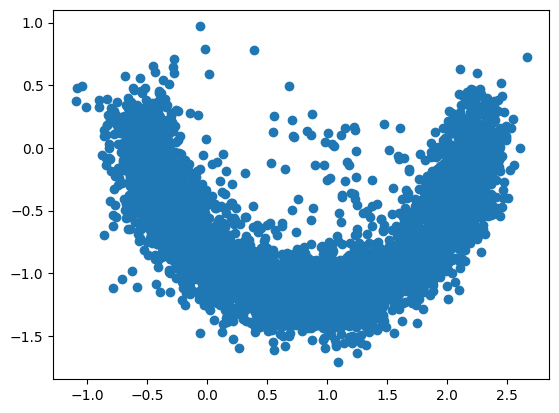

In [18]:
xt = cl_sample(2, 5000)
plt.scatter(xt[:, 0], xt[:, 1])

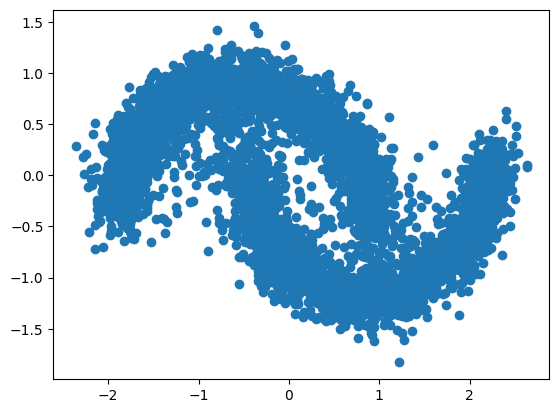

In [20]:
xt = nu_sample(2, 5000)
plt.scatter(xt[:, 0], xt[:, 1])

In [27]:
# an_results = []
# cl_results = []
# nu_results = []

# for i in range(5):
#     idx = torch.randperm(xt.shape[0])
#     X_real = torch.tensor(x[y == 1])[:xt.shape[0]][idx]

    
#     X_gen = an_sample(2, 5000).cpu().to(torch.float64)
#     _mmd = mmd(X_real, X_gen, sigma=0.5)
#     _xy_cov, _yx_cov = knn_fraction_coverage_both(X_gen, X_real, 3)
#     an_results.append((_mmd.item(), _xy_cov.item(), _yx_cov.item()))
    

#     X_gen = cl_sample(2, 5000).cpu().to(torch.float64)
#     _mmd = mmd(X_real, X_gen, sigma=0.5)
#     _xy_cov, _yx_cov = knn_fraction_coverage_both(X_gen, X_real, 3)
#     cl_results.append((_mmd.item(), _xy_cov.item(), _yx_cov.item()))

#     X_gen = nu_sample(2, 5000).cpu().to(torch.float64)
#     _mmd = mmd(X_real, X_gen, sigma=0.5)
#     _xy_cov, _yx_cov = knn_fraction_coverage_both(X_gen, X_real, 3)
#     nu_results.append((_mmd.item(), _xy_cov.item(), _yx_cov.item()))


In [28]:
# torch.save(an_results, "an_results.pt")
# torch.save(cl_results, "cl_results.pt")
# torch.save(nu_results, "nu_results.pt")

an_results = torch.load("an_results.pt")
cl_results = torch.load("cl_results.pt")
nu_results = torch.load("nu_results.pt")

In [33]:
an_sd = torch.sum((torch.tensor(an_results) - torch.tensor(an_results).mean(dim=0))**2, dim=0).sqrt() / (len(an_results) - 1)
cl_sd = torch.sum((torch.tensor(cl_results) - torch.tensor(cl_results).mean(dim=0))**2, dim=0).sqrt() / (len(cl_results) - 1)
nu_sd = torch.sum((torch.tensor(nu_results) - torch.tensor(nu_results).mean(dim=0))**2, dim=0).sqrt() / (len(nu_results) - 1)

nu_sd, cl_sd, an_sd, 

(tensor([0.0029, 0.0058, 0.0006]),
 tensor([0.0001, 0.0011, 0.0001]),
 tensor([0.0003, 0.0010, 0.0011]))

In [34]:
torch.tensor(nu_results).mean(dim=0), torch.tensor(cl_results).mean(dim=0) , torch.tensor(an_results).mean(dim=0), 

(tensor([0.1316, 0.4478, 0.9936]),
 tensor([0.0019, 0.9640, 0.9980]),
 tensor([0.0090, 0.9820, 0.9825]))